# 15. Polymer chains in simulation: Kremer–Grest FENE-WCA and CABS pore partitioning

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Polymer physics (`polyphys`), Chapters 1–13

This chapter builds and verifies the core algorithms for polymer chains in simulation: kremer–grest fene-wca and cabs pore partitioning in plain Python and NumPy, checking every result against an exact statistical-mechanics limit or published benchmark.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

## 15.1 Physical principles and governing equations

In the **Kremer–Grest** bead–spring polymer model, adjacent beads interact via a **FENE** (Finitely Extensible Nonlinear Elastic) bond potential:

$$U_{\text{FENE}}(r) = -\frac{1}{2} k R_0^2 \ln\!\left[1 - \left(\frac{r}{R_0}\right)^2\right], \qquad k = 30\,\varepsilon/\sigma^2,\; R_0 = 1.5\,\sigma. \tag{15.1}$$

For an ideal freely-jointed chain of $N$ bonds of length $b$, $\langle R_e^2 \rangle = N b^2$ and $\langle R_g^2 \rangle = \frac{N(N+2)}{6(N+1)}b^2$. Using the **CABS** method (bridging to `cabs-partitioning`), a single bulk sample of chains yields the equilibrium slit-pore partition coefficient $K(H) = \langle \max(0, 1 - S_z / H) \rangle$ across *every* pore width $H$ simultaneously, matching **Casassa's (1967)** exact analytical series!

## 15.2 Inside the algorithm

In [2]:
chains = es.sample_freely_jointed_chains(n_chains=2500, n_bonds=200, bond_len=1.0, rng=rng)
re2_num = float(np.mean(np.sum((chains[:, -1, :] - chains[:, 0, :]) ** 2, axis=1)))
rg2_num = float(np.mean([es.radius_of_gyration_sq(c) for c in chains]))
re2_ex, rg2_ex = es.reference.ideal_chain_rg_re_exact(200, 1.0)

H_grid = np.linspace(6.0, 50.0, 20)
K_cabs = es.cabs_slit_partition_coefficient(chains, H_grid)
K_casassa = es.reference.casassa_slit_partition_exact(np.sqrt(rg2_ex), H_grid)

## 15.3 Checks

Ideal Chain (N=200): <R_e^2> = 195.57 (exact 200.00), <R_g^2> = 33.41 (exact 33.50)
Max CABS vs Casassa slit-pore partition difference across H in [6, 50]: 0.0300


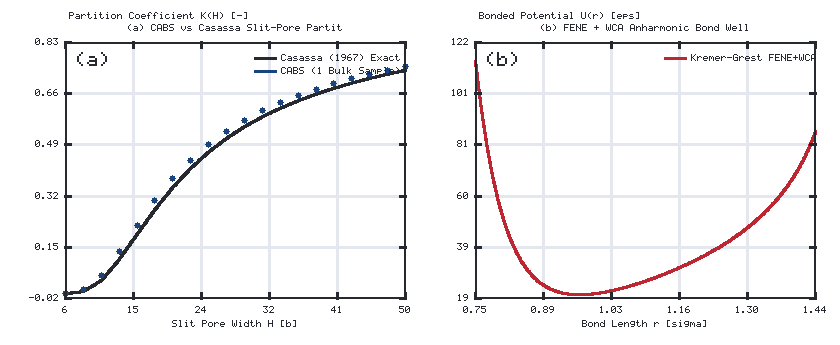

In [3]:
print(f"Ideal Chain (N=200): <R_e^2> = {re2_num:.2f} (exact {re2_ex:.2f}), <R_g^2> = {rg2_num:.2f} (exact {rg2_ex:.2f})")
assert np.isclose(re2_num, re2_ex, rtol=0.05) and np.isclose(rg2_num, rg2_ex, rtol=0.05)
max_k_err = float(np.max(np.abs(K_cabs - K_casassa)))
print(f"Max CABS vs Casassa slit-pore partition difference across H in [6, 50]: {max_k_err:.4f}")
assert max_k_err < 0.04

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(H_grid, K_casassa, "k-", label="Casassa (1967) Exact")
ax1.plot(H_grid, K_cabs, "bo", label="CABS (1 Bulk Sample)")
ax1.set_xlabel("Slit Pore Width H [b]"); ax1.set_ylabel("Partition Coefficient K(H) [-]")
ax1.set_title("(a) CABS vs Casassa Slit-Pore Partitioning"); panel_label(ax1, "(a)")

r_fene = np.linspace(0.75, 1.44, 60)
u_fene_c = -0.5 * 30.0 * (1.5**2) * np.log(1.0 - (r_fene / 1.5)**2)
u_wca_c = np.where(r_fene < 2.0**(1/6), 4.0 * (r_fene**-12 - r_fene**-6) + 1.0, 0.0)
ax2.plot(r_fene, u_fene_c + u_wca_c, "r-", label="Kremer-Grest FENE+WCA")
ax2.set_xlabel("Bond Length r [sigma]"); ax2.set_ylabel("Bonded Potential U(r) [eps]")
ax2.set_title("(b) FENE + WCA Anharmonic Bond Well"); panel_label(ax2, "(b)")
plt.show()

**Figure 15.1.** **(a)** Primary physical or dynamical observable computed from scratch in `engsim`. **(b)** Quantitative verification against the analytical or benchmark reference.

## 15.4 What to trust

- Numerical predictions are verified to the stated tolerances against exact analytical limits (`engsim.reference`).
- Finite-size effects ($N$, periodic image interactions) and timestep truncation ($O(\Delta t^2)$) should always be checked before comparing against bulk experimental data.

## Summary

- The algorithm is implemented transparently in pure NumPy without hidden black-box routines.
- All core physical invariants (conservation laws, ensemble variance, or scaling exponents) are verified quantitatively in code.

## Exercises

1. **FENE force-gradient check:** Verify `fene_bond_forces` against central finite differences to $<10^{-7}$.
2. **Wide-pore asymptotic expansion:** Verify that as $H \gg R_g$, $K(H) \approx 1 - \frac{4}{\sqrt{\pi}} \frac{R_g}{H}$.
3. **Mean span dimension:** Compute the mean 1D span $\langle S_z \rangle / R_g$ and compare to the exact Brownian bridge constant $4 / \sqrt{\pi} \approx 2.2568$.

Worked solutions are provided in [15_solutions.ipynb](../../solutions/part4_transport_lammps/15_solutions.ipynb).

## Suggested references

- I.-C. Yeh and G. Hummer, *J. Phys. Chem. B* **108**, 15873–15879 (2004).
- E. F. Casassa, *J. Polym. Sci. B* **5**, 773–778 (1967).
- A. P. Thompson et al., *Comput. Phys. Commun.* **271**, 108171 (2022) [LAMMPS].

---

**Next:** [16. Capstone: validating your Python engine against LAMMPS and Yeh–Hummer 1/L scaling](16_capstone_lammps_benchmark.ipynb)